# SentimentScope: Sentiment Analysis using Transformers!
## Introduction <a name = "introduction"></a>

In this notebook, you will train a transformer model from scratch to perform sentiment analysis on the IMDB dataset. You are a Machine Learning Engineer at Cinescope, a growing entertainment company working to enhance its recommendation system. Your task is to fine-tune a transformer-based model for sentiment analysis using the IMDB dataset. By classifying reviews as positive or negative, you will help the company better understand user sentiment and deliver more personalized experiences.

By completing this project, you will demonstrate your competency in the following learning objectives:

- Load, explore, and prepare a text dataset for training a transformer model using PyTorch.
- Customize the architecture of the transformer model for a classification task.
- Train and test a transformer model on the IMDB dataset.

Now that you have an overview of what you will achieve in this project, let’s move on to the project outline.

---

### Project Outline

This notebook is organized into the following sections:


1. [Introduction](#introduction): Overview of the project, learning objectives, and understanding sentiment analysis.
2. [Load, Explore, and Prepare the Dataset](#load-explore-and-prepare-the-dataset): Load the IMDB dataset, explore it with visualizations, and split it into training and validation sets.
3. [Implement a DataLoader in PyTorch](#implement-a-dataloader-in-pytorch): Create the `IMDBDataset` class and use it with the PyTorch `DataLoader`, including tokenization.
4. [Customize the Transformer Architecture](#customize-the-transformer-architecture): Modify the transformer model for binary classification.
5. [Implement Accuracy Calculation Method](#implement-accuracy-calculation-method): Create a function to compute accuracy for monitoring performance.
6. [Train the Model](#train-the-model): Complete and execute the training loop for binary classification.
7. [Test the Model](#test-the-model): Evaluate the model on the test dataset and ensure it achieves over 75% accuracy.
8. [Conclusion](#conclusion): Summarize the project results and key takeaways.

Click on the section titles above to navigate directly to the corresponding part of the notebook!

---

Now that we've outlined the structure and objectives of this project, let's delve into the core concept: sentiment analysis.

### Understanding Sentiment Analysis

Sentiment analysis is a natural language processing (NLP) technique used to determine the sentiment expressed in a piece of text. This can range from identifying the polarity (positive, negative, or neutral) of a review to analyzing emotions and opinions.

In this project, sentiment analysis is explicitly framed as a **binary classification task**, where the goal is to determine whether a given movie review is *positive* or *negative*. This task is central to many real-world applications, including customer feedback analysis, social media monitoring, and recommendation systems. By developing a transformer-based model, you will classify IMDB movie reviews as positive or negative to tackle the challenge faced by your entertainment company CineScope by enhancing its recommendation system, enabling more accurate and personalized suggestions. 

Reviews labeled as positive will be marked as 1 in the dataset, while negative reviews will be labeled as 0.

For example, consider the following movie review:

> "The movie was a rollercoaster of emotions, and I loved every moment of it!"

This review is clearly positive as it expresses enjoyment and satisfaction with the movie, hence it will be labelled as *positive* or 1 in the dataset. In contrast:

> "The plot was predictable, and the acting was subpar. A waste of time."

This review conveys a negative sentiment, criticizing both the plot and acting, hence it will be labelled as *negative* or 0 in the dataset.

While transformers are often used for generation tasks, they can also be adapted for classification tasks with some modifications to their architecture. You might already be familiar with the tweaks that we will implement in this project.


---

### Data Description

The dataset used in this project is the [IMDB dataset](https://ai.stanford.edu/~amaas/data/sentiment/), provided in the `aclIMDB_v1.tar.gz` file. Upon extracting the file, you will find the following folder structure:

```
aclIMDB/
├── train/
│   ├── pos/    # Positive reviews for training
│   ├── neg/    # Negative reviews for training
│   ├── unsup/  # Unsupervised data (not used in this project)
├── test/
│   ├── pos/    # Positive reviews for testing
│   ├── neg/    # Negative reviews for testing
```

- **train/**: Contains labeled data for training the model. Reviews in the `pos/` folder should be labeled as positive (1), while reviews in the `neg/` folder should be labeled as negative (0).
- **test/**: Contains labeled data for evaluating the model. Similar to the training data, `pos/` and `neg/` contain positive and negative reviews, respectively.
- **unsup/**: Contains unlabeled reviews that are not used in this project.

Understanding the folder structure is crucial as it guides how we load and preprocess the data for the sentiment classification task.

---


In [1]:
import sys
import torch
import transformers

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Apple GPU available:", torch.backends.mps.is_available())

/Users/rafiatasafi/Downloads/1792282720/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: /Users/rafiatasafi/Downloads/1792282720/.venv/bin/python
PyTorch: 2.14.1
Transformers: 4.57.6
Apple GPU available: True


## <a name="load-explore-and-prepare-the-dataset"></a>Load, Explore, and Prepare the Dataset

### 1. Load the Dataset
The dataset is already available in the environment as `aclIMDB_v1.tar.gz`. We will load it into Pandas DataFrames for easy exploration and preparation.


In [2]:
import os
import re
import html
import random
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
# Supports launching Jupyter from the repository root or the starter folder.
DATA_DIR = Path.cwd() if (Path.cwd() / "aclImdb_v1.tar.gz").exists() else Path.cwd() / "starter"
ARTIFACT_DIR = DATA_DIR / "artifacts"
ARTIFACT_DIR.mkdir(exist_ok=True)

def clean_review(text):
    # Preserve punctuation and negation, both useful for sentiment.
    return re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", text))).strip()

Matplotlib is building the font cache; this may take a moment.


In [3]:
import tarfile

if not (DATA_DIR / "aclImdb" / "train" / "pos").is_dir():
    with tarfile.open(DATA_DIR / "aclImdb_v1.tar.gz", "r:gz") as archive:
        # Only extract expected review files; reject traversal and links.
        destination = DATA_DIR.resolve()
        members = []
        for member in archive.getmembers():
            target = (destination / member.name).resolve()
            if not target.is_relative_to(destination):
                raise ValueError("Unsafe archive path")
            parts = Path(member.name).parts
            if (member.isfile() and len(parts) == 4 and parts[0] == "aclImdb"
                    and parts[1] in {"train", "test"} and parts[2] in {"pos", "neg"}
                    and parts[3].endswith(".txt")):
                members.append(member)
        archive.extractall(destination, members=members, filter="data")
print("Dataset directory:", DATA_DIR / "aclImdb")

Dataset directory: /Users/rafiatasafi/Downloads/1792282720/starter/aclImdb


You have successfully extracted the folder. Go back to your workspace and explore the folder structure and find the relative paths for each of the following:
- Training positive reviews
- Training negative reviews
- Testing positive reviews
- Testing negative reviews

Assign the paths of these folders relative to the starter file in the variables below.


In [4]:
train_pos_path = DATA_DIR / "aclImdb/train/pos"
train_neg_path = DATA_DIR / "aclImdb/train/neg"
test_pos_path = DATA_DIR / "aclImdb/test/pos"
test_neg_path = DATA_DIR / "aclImdb/test/neg"

Now, you will implement the `load_dataset()` function, which reads all text files in a specified folder and returns their content as a list of strings. This function is essential for loading and preprocessing the dataset in subsequent steps.

To implement this function:

1. **Use the `os` module**: Leverage Python's `os` module to list all files in the folder.
2. **Handle file paths**: Use `os.path.join()` to construct full paths for files, ensuring compatibility across operating systems.
3. **Read file content**: Open each file in read mode (`'r'`) using UTF-8 encoding to handle text properly.
4. **Aggregate results**: Append the content of each file to a list and return it.

### Key Points to Consider:
- Ensure that the function only processes text files (you may use file extensions for filtering if needed).
- Refer to the [os.listdir documentation](https://docs.python.org/3/library/os.html#os.listdir) for listing files in a directory.


In [5]:
def load_dataset(folder):
    """Load labeled review text files in deterministic filename order."""
    return [clean_review((Path(folder) / name).read_text(encoding="utf-8"))
            for name in sorted(os.listdir(folder)) if name.endswith(".txt")]

Use the function now to load the training and testing data:

In [6]:
train_pos = load_dataset(train_pos_path)
train_neg = load_dataset(train_neg_path)
test_pos = load_dataset(test_pos_path)
test_neg = load_dataset(test_neg_path)

We can convert the data into pandas dataframes to make handling the datasets easier.

In [7]:
# Create DataFrames
train_df = pd.DataFrame({
    'review': train_pos + train_neg,
    'label': [1] * len(train_pos) + [0] * len(train_neg)
})

test_df = pd.DataFrame({
    'review': test_pos + test_neg,
    'label': [1] * len(test_pos) + [0] * len(test_neg)
})

print(train_df.head())

                                              review  label
0  Bromwell High is a cartoon comedy. It ran at t...      1
1  Homelessness (or Houselessness as George Carli...      1
2  Brilliant over-acting by Lesley Ann Warren. Be...      1
3  This is easily the most underrated film inn th...      1
4  This is not the typical Mel Brooks film. It wa...      1


You can ensure that your datasets have loaded correctly by running the following code cell. No output means success!

In [8]:
# Assert that both datasets have the expected number of rows
assert train_df.shape[0] == 25000, "Training dataset does not have 25000 rows."
assert test_df.shape[0] == 25000, "Testing dataset does not have 25000 rows."

# Assert that both datasets have exactly two columns
assert train_df.shape[1] == 2, "Training dataset does not have exactly 2 columns."
assert test_df.shape[1] == 2, "Testing dataset does not have exactly 2 columns."


### 2. Explore the Dataset
Exploration helps us understand the dataset's structure and distribution.

Here are some suggestions for exploration and visualizations:
- **Dataset Overview**: Use `DataFrame.info()` and `DataFrame.describe()` to understand the dataset structure and basic statistics.
- **Label Distribution**: Create bar charts to visualize the number of positive and negative reviews.
- **Review Length Analysis**: Compute and plot the distribution of review lengths (e.g., number of characters or words).
- **Sample Reviews**: Print a few positive and negative reviews to understand the text content.

Write code to explore the dataset in this section.

In [9]:
for name, frame in [("Training", train_df), ("Test", test_df)]:
    print(f"\n{name}: shape={frame.shape}; missing values={frame.isna().sum().sum()}")
    print("Label counts (0=negative, 1=positive):", frame.label.value_counts().sort_index().to_dict())
    lengths = frame.review.str.split().str.len()
    print("Review word counts:")
    print(lengths.describe(percentiles=[.5, .9, .95, .99]))
    print("Duplicate review text count:", frame.review.duplicated().sum())


Training: shape=(25000, 2); missing values=0
Label counts (0=negative, 1=positive): {0: 12500, 1: 12500}
Review word counts:
count    25000.00000
mean       231.48264
std        171.98452
min         10.00000
50%        173.00000
90%        454.00000
95%        592.05000
99%        907.00000
max       2459.00000
Name: review, dtype: float64
Duplicate review text count: 98

Test: shape=(25000, 2); missing values=0
Label counts (0=negative, 1=positive): {0: 12500, 1: 12500}
Review word counts:
count    25000.000000
mean       226.249240
std        167.121842
min          4.000000
50%        170.000000
90%        439.000000
95%        576.000000
99%        889.020000
max       2235.000000
Name: review, dtype: float64
Duplicate review text count: 201


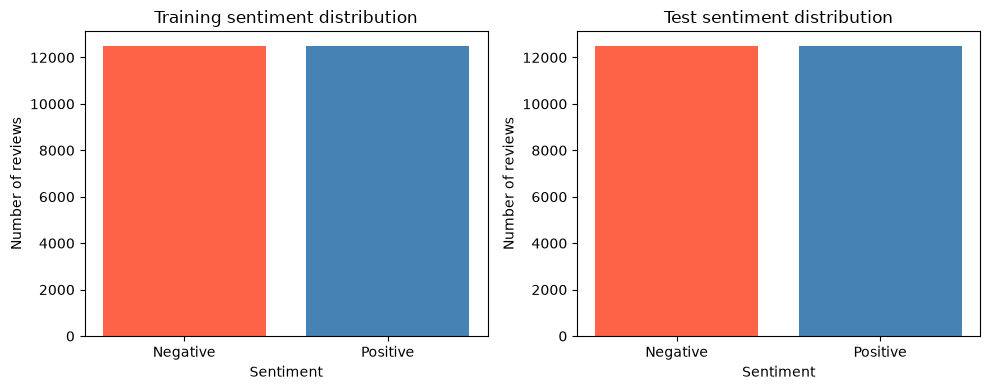

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, frame) in zip(axes, [("Training", train_df), ("Test", test_df)]):
    counts = frame.label.value_counts().reindex([0, 1])
    ax.bar(["Negative", "Positive"], counts, color=["tomato", "steelblue"])
    ax.set(title=f"{name} sentiment distribution", xlabel="Sentiment", ylabel="Number of reviews")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "label_distribution.png", dpi=150)
plt.show()

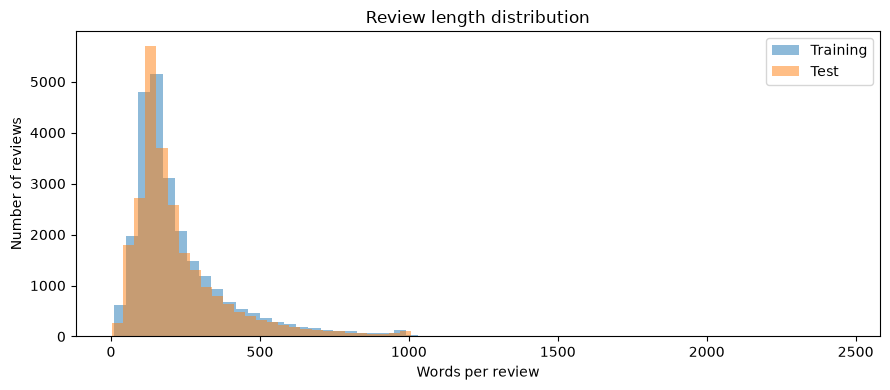

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, frame in [("Training", train_df), ("Test", test_df)]:
    ax.hist(frame.review.str.split().str.len(), bins=60, alpha=.5, label=name)
ax.set(title="Review length distribution", xlabel="Words per review", ylabel="Number of reviews")
ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "review_lengths.png", dpi=150)
plt.show()

In [12]:
for label in [0, 1]:
    print(f"\n{'Positive' if label else 'Negative'} sample:")
    print(train_df.loc[train_df.label == label, "review"].iloc[0][:800])


Negative sample:
Story of a man who has unnatural feelings for a pig. Starts out with a opening scene that is a terrific example of absurd comedy. A formal orchestra audience is turned into an insane, violent mob by the crazy chantings of it's singers. Unfortunately it stays absurd the WHOLE time with no general narrative eventually making it just too off putting. Even those from the era should be turned off. The cryptic dialogue would make Shakespeare seem easy to a third grader. On a technical level it's better than you might think with some good cinematography by future great Vilmos Zsigmond. Future stars Sally Kirkland and Frederic Forrest can be seen briefly.

Positive sample:
Bromwell High is a cartoon comedy. It ran at the same time as some other programs about school life, such as "Teachers". My 35 years in the teaching profession lead me to believe that Bromwell High's satire is much closer to reality than is "Teachers". The scramble to survive financially, the insightful stu

### 3. Prepare the Dataset
We will split the training data further into training and validation subsets. The way we constructed the dataset, reviews with positive and negative labels are segregated. To ensure that the validation dataset works well, we first need to shuffle the dataset.


In [13]:
from sklearn.model_selection import train_test_split

train_data, val_data = train_test_split(
    train_df, test_size=0.1, random_state=SEED, stratify=train_df["label"]
)
train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)
print("Split sizes:", len(train_data), len(val_data), len(test_df))
print("Training proportions:", train_data.label.value_counts(normalize=True).to_dict())
print("Validation proportions:", val_data.label.value_counts(normalize=True).to_dict())

Split sizes: 22500 2500 25000
Training proportions: {0: 0.5, 1: 0.5}
Validation proportions: {0: 0.5, 1: 0.5}


### 4. Testing the Tokenizer

#### Subword Tokenization
In earlier tasks, you might have encountered character-level tokenization, where each character in the text is treated as a token. While this is straightforward, it is less efficient and may result in larger input sizes, impacting the performance of transformer models.

To address this, we will use Hugging Face's `AutoTokenizer`, a robust and efficient class designed for tokenizing text based on pretrained models. Specifically, we will utilize the `bert-base-uncased` tokenizer, which applies **subword tokenization**. Subword tokenization involves two steps:

1. **Subword Splitting**: Words are split into smaller components (subwords) based on a predefined vocabulary. For example:
   - Input: "unhappiness"
   - Subword Splits: `['un', 'happiness']`

2. **Token Conversion**: Each subword is then converted into a numerical token ID. For example:
   - Subword Splits: `['un', 'happiness']`
   - Token IDs: `[1011, 24123]` (values are illustrative and depend on the tokenizer vocabulary).

#### About the `bert-base-uncased` Tokenizer
The `bert-base-uncased` tokenizer, developed by Google researchers, is part of the BERT model family. This tokenizer is associated with the `bert-base-uncased` model, which has been widely used for tasks such as sentiment analysis, question answering, and text classification. The tokenizer ensures all text is converted to lowercase and accents are removed, reducing vocabulary size and improving generalization. Example:

- Input: "I Love Transformers."
- Subword Splits: `['i', 'love', 'trans', '##formers', '.']`

You can learn more about the tokenizer and model on [Hugging Face's bert-base-uncased page](https://huggingface.co/bert-base-uncased).

#### Using the `AutoTokenizer` Class
The `AutoTokenizer` class in the Hugging Face Transformers library provides a seamless way to load tokenizers for various pretrained models. It automatically selects the correct tokenizer configuration based on the model name.


In [14]:
from transformers import AutoTokenizer

# Initialize tokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

This initializes a tokenizer tailored for the `bert-base-uncased` model. You can refer to the [Hugging Face AutoTokenizer documentation](https://huggingface.co/docs/transformers/main_classes/tokenizer) for more details. You can find the definition of the `from_pretrained()` method [here](https://huggingface.co/docs/transformers/v4.48.0/en/model_doc/auto#transformers.AutoTokenizer.from_pretrained).

Instead of tokenizing the entire dataset, we will test the tokenizer on a few sample reviews directly from the dataset:


In [15]:
# Take sample inputs from the dataset
sample_texts = train_data['review'].sample(3, random_state=42).tolist()

# Tokenize sample inputs
tokenized_samples = tokenizer(sample_texts, truncation=True, padding="max_length", max_length=128, return_tensors="pt")

In [16]:
print(tokenized_samples)

{'input_ids': tensor([[  101, 14665,  2048,  4898,  5998,  2000,  3143,  2037,  2808,  1999,
          2019,  2035,  2021,  4064,  4545,  2160,  1012,  2027,  2012,  2034,
          2393,  2169,  2060,  1998,  2059,  3254,  1996,  6980,  2090,  2068,
          4269,  2000,  3857,  1012,  2023,  2003,  2241,  2588,  1037,  6795,
         28935, 12274,  2094,  3117,  1998,  6854,  3071,  8847,  2004,  2295,
          2027,  2024,  1999,  2008,  3117,  1012,  2200,  2210,  1997,  1996,
         13764,  8649,  2003,  3019,  1010,  2049,  6379,  1998,  7987,  5714,
          6562,  2007, 13178,  1997,  3574,  1012,  2049,  2004,  2065,  1037,
          2267,  2394,  2350,  2007,  1037,  2132,  2440,  1997,  3653, 29048,
          2015,  2626,  1996,  5896,  1012,  2009,  1005,  1055,  9643,  1998,
          1045,  2179,  2870,  6880, 11311,  2000,  2505,  1996,  2143,  2018,
          2000,  2360,  1010,  2029,  2003,  1037,  9467,  2144,  1996,  2143,
          2003, 10357,  2007,  2307,  

Explanation of parameters:
 - `truncation=True`: Truncates text longer than the specified max_length.
 - `padding=True`: Pads shorter sequences to match max_length.
 - `max_length=128`: Specifies the maximum length of the sequences.
 - `return_tensors="pt"`: Returns PyTorch tensors as the output format.
 
For more details about truncation and padding, refer to the [Hugging Face Padding and Truncation Documentation](https://huggingface.co/docs/transformers/pad_truncation). This step ensures that the tokenizer works as expected and provides insight into its behavior. Next, we will use the tokenizer within the class definition to process the dataset.

---


# Implement a DataLoader in PyTorch<a id="implement-a-dataloader-in-pytorch"></a>


In this section, you will implement a custom dataset class and use it to create a DataLoader in PyTorch for feeding data into the model during training. PyTorch simplifies this process by providing the `Dataset` and `DataLoader` classes, which handle batching, shuffling, and preprocessing, allowing you to focus on the model architecture and training.

To start, we will create a custom dataset class for the IMDB dataset, which will process and return tokenized inputs along with their corresponding labels. This class will use a tokenizer to preprocess the raw text data.

### 1. Define a Custom Dataset Class

The custom dataset class will inherit from `torch.utils.data.Dataset` and include the following features:

1. **Initialization (`__init__`)**:
   - Accepts raw text and label data, along with a tokenizer and a maximum sequence length.
   - The tokenizer is used to preprocess the text data into tokenized inputs.
   - The maximum sequence length ensures that all tokenized inputs are of uniform length.

2. **Length (`__len__`)**:
   - Returns the total number of data samples in the dataset.

3. **Item Retrieval (`__getitem__`)**:
   - Retrieves a single data point by index.
   - Preprocesses the text using the tokenizer to create tokenized input IDs.
   - Returns the tokenized input IDs and the corresponding label for the given index.

You can refer to [this](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html) tutorial on the Pytorch website for more details.


In [17]:
import torch
from torch.utils.data import Dataset
MAX_LENGTH = 128

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Using device:", device)
# Seeds improve repeatability; exact results may differ across devices/versions.

Using device: mps


**NOTE ABOUT GPU USAGE**

The workspace provides you with access to a GPU which is necessary for training a transformer model due to the efficiency provided by GPUs on the large amount of computations that are required. To ensure judicious usage of limited resources, please usage the GPU only when you are training the model. 

---
We will keep the maximum length of input to 128 tokens.

In [18]:
class IMDBDataset(Dataset):
    """Tokenize each review; return fixed-length IDs and an integer label."""
    def __init__(self, data, tokenizer, max_length=MAX_LENGTH):
        self.data = data.reset_index(drop=True).copy()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        encoded = self.tokenizer(
            row["review"], padding="max_length", truncation=True,
            max_length=self.max_length, return_tensors="pt"
        )
        return encoded["input_ids"].squeeze(0), int(row["label"])

### 2. Initialize the Dataset

Once the `IMDBDataset` class is defined, we can initialize it directly with the training and validation DataFrames.

In [19]:
# Initialize the datasets
train_dataset = IMDBDataset(train_data, tokenizer)
val_dataset = IMDBDataset(val_data, tokenizer)
test_dataset = IMDBDataset(test_df, tokenizer)

### 3. Create a DataLoader

The `DataLoader` class in PyTorch helps manage batches of data during training. We will use it to create training and validation data loaders.

In [20]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32
loader_generator = torch.Generator().manual_seed(SEED)
# num_workers=0 works in notebooks on macOS and the course workspace.
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          generator=loader_generator, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


You may have seen the use of `RandomShuffler` along with `DataLoader`. That approach is used when you want to train a model over a dataset randomly for a specified number of steps. In this model, we want to use the epoch approach.

An **epoch** is one complete pass through the entire dataset. When using the `DataLoader` in this setup, it ensures that every data point in the dataset is used exactly once during a single epoch. This approach is helpful for training models in a structured manner, ensuring that the model sees all the training examples and learns from them in each epoch before moving to the next one.

By setting `shuffle=True` for the `train_loader`, the data points are randomly shuffled at the start of each epoch, improving the generalization of the model. You will see this in action later in the code for training the model.

---
Given below are some assert statements to check your custom dataset and data loader definitions.

In [21]:
assert len(train_dataset) == 22500, "Train dataset length mismatch!"
assert len(val_dataset) == 2500, "Validation dataset length mismatch!"
assert len(test_dataset) == 25000, "Test dataset length mismatch!"

import numpy as np

# Check the first item in the train dataset
input_ids, label = train_dataset[0]
assert isinstance(input_ids, torch.Tensor), "Input IDs should be a torch.Tensor!"
assert isinstance(label, (int, np.integer)), "Label should be an integer or int-like!"

# Ensure the input IDs tensor has the correct shape
assert input_ids.shape[0] == train_dataset.max_length, "Input IDs tensor has incorrect length!"

## <a id="customize-the-transformer-architecture"></a>Customize the Transformer Architecture

In this section, you will customize the transformer architecture to suit the task of binary classification. You may have used a similar architecture in the past for generation tasks. But you will need to make a few tweaks specifically in the `DemoGPT` class to adapt it for the binary classification.

### 1. Config Dictionary
Your config dictionary bundles all hyperparameters and model settings in one place. Below is the config that we will use in our model:

In [22]:
config = {
    "vocabulary_size": tokenizer.vocab_size,  # e.g., ~30522 for bert-base-uncased
    "num_classes": 2,                         # binary classification (pos/neg)
    "d_embed": 128,
    "context_size": MAX_LENGTH,
    "layers_num": 4,
    "heads_num": 4,
    "head_size": 32,  # 4 heads * 32 = 128 -> matches d_embed
    "dropout_rate": 0.1,
    "pad_token_id": tokenizer.pad_token_id,
    "use_bias": True
}

Key Config Parameters:
- `vocabulary_size`: The total number of tokens in your vocabulary.
- `num_classes`: The number of classes for the classification head (2 = binary).
- `d_embed`: Dimensionality of embeddings (and hidden layers).
- `context_size`: Maximum sequence length for each input.
- `layers_num`: Number of stacked transformer blocks.
- `heads_num`: Number of attention heads in multi-head attention.
- `head_size`: Dimension of each attention head (must satisfy heads_num * head_size = d_embed).
- `dropout_rate`: Probability of dropping units during training to reduce overfitting.
- `use_bias`: Whether linear layers should have bias terms.



### 2. Class Definitions

Below are the class definitions you will work with. These classes form the core components of the transformer model. You may have seen these before, with the exception of the `DemoGPT` class which will need to be customized.


#### AttentionHead

In [23]:
import torch.nn as nn
import math

class AttentionHead(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.Q_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])
        self.K_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])
        self.V_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])

        self.dropout = nn.Dropout(config["dropout_rate"])

        casual_attention_mask = torch.tril(torch.ones(config["context_size"], config["context_size"]))
        self.register_buffer('casual_attention_mask', casual_attention_mask)

    def forward(self, input):
        batch_size, tokens_num, d_embed = input.shape
        Q = self.Q_weights(input)  # (B, T, head_size)
        K = self.K_weights(input)  # (B, T, head_size)
        V = self.V_weights(input)  # (B, T, head_size)

        # Q @ K^T => (B, T, T)
        attention_scores = Q @ K.transpose(1, 2)

        # Casual Mask
        attention_scores = attention_scores.masked_fill(
            self.casual_attention_mask[:tokens_num, :tokens_num] == 0,
            float('-inf')
        )
        attention_scores = attention_scores / math.sqrt(K.shape[-1])
        attention_scores = torch.softmax(attention_scores, dim=-1)
        attention_scores = self.dropout(attention_scores)

        return attention_scores @ V

Here we use a dummy input aligned with our config:

- Batch size = `BATCH_SIZE` (32)
- Sequence length = `config["context_size"]` (128)
- Embedding dimension = `config["d_embed"]` (128)


In [24]:
# Instantiate the AttentionHead
attention_head = AttentionHead(config).to(device)

# Create a dummy input of shape (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
attention_output = attention_head(dummy_input)
print("AttentionHead output shape:", attention_output.shape)

AttentionHead output shape: torch.Size([32, 128, 32])


Expected shape:

>`(B,T,head_size)=(32,128,32)`

#### MultiHeadAttention


In [25]:
class MultiHeadAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        heads_list = [AttentionHead(config) for _ in range(config["heads_num"])]
        self.heads = nn.ModuleList(heads_list)

        self.linear = nn.Linear(config["heads_num"] * config["head_size"], config["d_embed"])
        self.dropout = nn.Dropout(config["dropout_rate"])

    def forward(self, input):
        heads_outputs = [head(input) for head in self.heads]
        x = torch.cat(heads_outputs, dim=-1)  # (B, T, heads_num * head_size)
        x = self.linear(x)                   # (B, T, d_embed)
        x = self.dropout(x)
        return x

In [26]:
# Instantiate MultiHeadAttention
multi_head_attention = MultiHeadAttention(config).to(device)

# Same dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
mha_output = multi_head_attention(dummy_input)
print("MultiHeadAttention output shape:", mha_output.shape)

MultiHeadAttention output shape: torch.Size([32, 128, 128])


Expected shape:

>`(B,T,d_embed)=(32,128,128)`

#### FeedForward


In [27]:
class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.linear_layers = nn.Sequential(
            nn.Linear(config["d_embed"], 4 * config["d_embed"]),
            nn.GELU(),
            nn.Linear(4 * config["d_embed"], config["d_embed"]),
            nn.Dropout(config["dropout_rate"])
        )

    def forward(self, input):
        return self.linear_layers(input)

In [28]:
# Instantiate FeedForward
feed_forward = FeedForward(config).to(device)

# Dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
ff_output = feed_forward(dummy_input)
print("FeedForward output shape:", ff_output.shape)

FeedForward output shape: torch.Size([32, 128, 128])


Expected shape:

>`(B,T,d_embed)=(32,128,128)`

#### Block


In [29]:
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.multi_head = MultiHeadAttention(config)
        self.layer_norm_1 = nn.LayerNorm(config["d_embed"])

        self.feed_forward = FeedForward(config)
        self.layer_norm_2 = nn.LayerNorm(config["d_embed"])

    def forward(self, input):
        x = input
        x = x + self.multi_head(self.layer_norm_1(x))
        x = x + self.feed_forward(self.layer_norm_2(x))
        return x

In [30]:
# Instantiate a single Block
block = Block(config).to(device)

# Dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
block_output = block(dummy_input)
print("Block output shape:", block_output.shape)

Block output shape: torch.Size([32, 128, 128])


Expected shape:

>`(B,T,d_embed)=(32,128,128)`

#### DemoGPT
Below is the starter code for the `DemoGPT` class, which implements the core of a transformer model tailored for a binary classification task. This implementation builds on the foundation of a transformer architecture and includes the necessary modifications to adapt it for classification. 

### Key Changes for Binary Classification

To adapt the transformer for classification, the following changes are required:

1. **Add a Classification-Specific Output Layer**:
   - The model needs a linear layer to map the final pooled embeddings to the number of classes. 
   - The classification head is implemented using [`torch.nn.Linear`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) with:
     - `in_features` set to `d_embed` (the embedding dimension).
     - `out_features` set to `num_classes` (the number of classes, 2 for binary classification).
     - `bias` set to `False` (optional; bias can be excluded to slightly simplify computations).


2. **Implement a Pooling Mechanism**:

   - Transformers output embeddings for each token in the input sequence. For classification, these token-level embeddings need to be condensed into a single vector.

   - A **mean pooling operation** is applied using [`torch.mean`](https://pytorch.org/docs/stable/generated/torch.mean.html) across the time dimension (`dim=1`) to aggregate token-level embeddings into a single representation vector.

In [31]:
class DemoGPT(nn.Module):
    def __init__(self, config):
        """
        Initialize the DemoGPT class with configuration parameters.

        Args:
        - config (dict): Configuration dictionary with the following keys:
            - "vocabulary_size": Size of the vocabulary.
            - "d_embed": Dimensionality of the embedding vectors.
            - "context_size": Maximum sequence length (context size).
            - "layers_num": Number of transformer layers.
            - "num_classes": Number of output classes (2 for binary classification).
        """
        super().__init__()
        # Token embedding layer: Maps token indices to embedding vectors.
        self.pad_token_id = config.get("pad_token_id", 0)
        self.token_embedding_layer = nn.Embedding(
            config["vocabulary_size"], config["d_embed"], padding_idx=self.pad_token_id)
        
        # Positional embedding layer: Adds positional information to the embeddings.
        self.positional_embedding_layer = nn.Embedding(config["context_size"], config["d_embed"])
        
        # Transformer layers: Stacked sequence of transformer blocks.
        blocks = [Block(config) for _ in range(config["layers_num"])]
        self.layers = nn.Sequential(*blocks)
        
        # Layer normalization: Applied to stabilize training.
        self.layer_norm = nn.LayerNorm(config["d_embed"])
        
        self.classifier = nn.Linear(config["d_embed"], config["num_classes"], bias=False)

    def forward(self, token_ids):
        """
        Forward pass of the model.

        Args:
        - token_ids (torch.Tensor): Input token indices of shape (B, T), 
                                    where B is the batch size, and T is the sequence length.
        
        Returns:
        - logits (torch.Tensor): Output logits of shape (B, num_classes).
        """
        batch_size, tokens_num = token_ids.shape

        # Step 1: Create embeddings for tokens and their positions
        x = self.token_embedding_layer(token_ids)  # Shape: (B, T, d_embed)
        positions = torch.arange(tokens_num, device=token_ids.device)  # Shape: (T,)
        pos_embed = self.positional_embedding_layer(positions)  # Shape: (T, d_embed)
        x = x + pos_embed.unsqueeze(0)  # Add positional embeddings to token embeddings
        
        # Step 2: Pass embeddings through transformer layers
        x = self.layers(x)  # Shape: (B, T, d_embed)
        x = self.layer_norm(x)  # Normalize across the feature dimension
        
        # Mean pool real tokens only. Right padding is required with causal attention.
        mask = token_ids.ne(self.pad_token_id).unsqueeze(-1).to(x.dtype)
        pooled = (x * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1)
        
        # Return raw logits for CrossEntropyLoss; softmax is used for inference.
        logits = self.classifier(pooled)
        
        return logits

In [32]:
# Instantiate the model
demo_gpt = DemoGPT(config).to(device)

# Suppose we have a batch of size 32, each with a sequence length of 128
dummy_token_ids = torch.randint(
    0, config["vocabulary_size"], 
    (BATCH_SIZE, config["context_size"])
).to(device)

# Forward pass
logits = demo_gpt(dummy_token_ids)

print("DemoGPT output shape:", logits.shape)
print("Logits sample:\n", logits[:2])  # Print first two examples' logits

DemoGPT output shape: torch.Size([32, 2])
Logits sample:
 tensor([[-0.1121,  0.0161],
        [-0.1241, -0.0633]], device='mps:0', grad_fn=<SliceBackward0>)


Expected shape:

> `(B,num_classes)=(32,2)`


In [33]:
# Assert that the number of logits matches the number of classes
assert logits.size(1) == config["num_classes"], (
    f"Expected number of classes {config['num_classes']}, "
    f"but got {logits.size(1)}"
)

# Assert that the batch size of the output matches the input batch size
assert logits.size(0) == BATCH_SIZE, (
    f"Expected batch size {BATCH_SIZE}, "
    f"but got {logits.size(0)}"
)

## Implement Accuracy Calculation Method <a name="implement-accuracy-calculation-method"></a>

In this section, you will learn how to calculate the validation accuracy for the transformer model on the IMDB dataset. Validation accuracy provides a performance metric that helps assess how well the model generalizes to unseen data during training.

### 1. Overview
The function to calculate validation accuracy will:

- Evaluate the model on the validation dataset.
- Generate predictions for each batch.
- Compare predictions with the true labels.
- Compute the percentage of correctly classified examples.

### 2.  Key Points
- **Evaluation Mode**: Calling `model.eval()` ensures that dropout and other training-specific layers are disabled during evaluation.
- **No Gradients**: The `torch.no_grad()` context disables gradient computation, reducing memory usage and speeding up validation.
- **Predictions**: `torch.argmax(logits, dim=1)` retrieves the index of the highest logit for each sample, which corresponds to the predicted class label.
- **Accuracy Calculation**: The function computes the fraction of correct predictions out of the total number of samples, then multiplies by 100 to express it as a percentage.

After calculating the validation accuracy, incorporate this function into your training loop. Typically, you would call calculate_accuracy at the end of each epoch or after a specific number of training steps. Monitoring validation accuracy over time helps you track performance gains and identify potential overfitting or underfitting issues.

In [34]:
@torch.no_grad()
def evaluate(model, data_loader, device):
    """Sample-weighted cross entropy and accuracy, without parameter updates."""
    was_training = model.training
    model.eval()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    try:
        for input_ids, labels in data_loader:
            input_ids, labels = input_ids.to(device), labels.to(device)
            logits = model(input_ids)
            total_loss += nn.functional.cross_entropy(logits, labels, reduction="sum").item()
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_samples += labels.size(0)
    finally:
        model.train(was_training)
    if total_samples == 0:
        raise ValueError("Cannot evaluate an empty dataset")
    return {"loss": total_loss / total_samples, "accuracy": 100.0 * total_correct / total_samples}

def calculate_accuracy(model, data_loader, device):
    """Return classification accuracy as a percentage."""
    return evaluate(model, data_loader, device)["accuracy"]

In [35]:
model = DemoGPT(config).to(device)

In [36]:
validation_accuracy = calculate_accuracy(model, val_loader, device)
print(f"Validation Accuracy: {validation_accuracy:.2f}%")

Validation Accuracy: 51.48%


As you can see, the validation accuracy is close to 50%. This is expected as the model's parameters have been initialized randomly. 

## Train the Model <a name="train-the-model"></a>

In this section, we will define the training loop for the transformer-based model designed for sentiment analysis. The training loop is crucial for optimizing the model's weights and biases to minimize the loss function and improve classification performance.

### Training Loop

The training loop will involve the following steps:

1. **Iterate through epochs**: Repeat the training process for a predefined number of epochs.
2. **Load batches of data**: Use the `DataLoader` to retrieve batches of input IDs and labels.
3. **Forward pass**: Compute the logits by passing the input IDs through the model.
4. **Compute loss**: Use cross-entropy loss as the criterion.
5. **Backward pass and optimization**: Backpropagate the loss and update the model parameters using the optimizer.
6. **Validation**: Calculate the validation accuracy after each epoch.


In [38]:
import json
import torch.optim as optim

EPOCHS = 10  # Tune using validation results only; stop early on a plateau.
LEARNING_RATE = 3e-4
PATIENCE = 3
model = DemoGPT(config).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
best_val_loss = float("inf")
stale_epochs = 0
history = []
checkpoint_path = ARTIFACT_DIR / "best_model.pt"
tokenizer.save_pretrained(ARTIFACT_DIR / "tokenizer")

for epoch in range(EPOCHS):
    model.train()
    total_loss, total_samples = 0.0, 0
    for step, (input_ids, labels) in enumerate(train_loader):
        input_ids, labels = input_ids.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(input_ids)
        loss = criterion(logits, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)
        if (step + 1) % 100 == 0:
            print(f"Epoch {epoch+1}, batch {step+1}/{len(train_loader)}, loss {loss.item():.4f}")

    validation = evaluate(model, val_loader, device)
    record = {"epoch": epoch + 1, "train_loss": total_loss / total_samples,
              "val_loss": validation["loss"], "val_accuracy": validation["accuracy"]}
    history.append(record)
    print(record)
    (ARTIFACT_DIR / "history.json").write_text(json.dumps(history, indent=2))
    if validation["loss"] < best_val_loss:
        best_val_loss = validation["loss"]
        stale_epochs = 0
        torch.save({"model_state_dict": model.state_dict(), "config": config,
                    "epoch": epoch + 1, "validation": validation, "seed": SEED,
                    "learning_rate": LEARNING_RATE, "batch_size": BATCH_SIZE}, checkpoint_path)
    else:
        stale_epochs += 1
        if stale_epochs >= PATIENCE:
            print("Early stopping: validation loss has stopped improving.")
            break

# Restore the checkpoint selected exclusively by validation loss.
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
print("Restored best epoch:", checkpoint["epoch"])

Epoch 1, batch 100/704, loss 0.6738
Epoch 1, batch 200/704, loss 0.7049
Epoch 1, batch 300/704, loss 0.5841
Epoch 1, batch 400/704, loss 0.6156
Epoch 1, batch 500/704, loss 0.6712
Epoch 1, batch 600/704, loss 0.5890
Epoch 1, batch 700/704, loss 0.5614
{'epoch': 1, 'train_loss': 0.6205377292527093, 'val_loss': 0.5894498319625855, 'val_accuracy': 68.28}
Epoch 2, batch 100/704, loss 0.5286
Epoch 2, batch 200/704, loss 0.5012
Epoch 2, batch 300/704, loss 0.4789
Epoch 2, batch 400/704, loss 0.4317
Epoch 2, batch 500/704, loss 0.4088
Epoch 2, batch 600/704, loss 0.3447
Epoch 2, batch 700/704, loss 0.4783
{'epoch': 2, 'train_loss': 0.4912905955950419, 'val_loss': 0.48874025247097014, 'val_accuracy': 76.6}
Epoch 3, batch 100/704, loss 0.4859
Epoch 3, batch 200/704, loss 0.5377
Epoch 3, batch 300/704, loss 0.4817
Epoch 3, batch 400/704, loss 0.3798
Epoch 3, batch 500/704, loss 0.3402
Epoch 3, batch 600/704, loss 0.5915
Epoch 3, batch 700/704, loss 0.3928
{'epoch': 3, 'train_loss': 0.41864729545

Training uses raw logits with cross-entropy loss, gradient clipping, and AdamW.
Epoch losses are weighted by the number of reviews. Validation loss selects the checkpoint;
validation accuracy tracks progress. The held-out test split is not used for model selection.
The ten-epoch budget is a starting point, not an accuracy guarantee.

## Test the Model <a name="test-the-model"></a>

In this section, you will evaluate the performance of your trained transformer model on the test dataset. Testing the model involves loading the test dataset, passing it through the model, and calculating the accuracy.

Test loss: 0.4928
Test accuracy: 75.35%
Rubric target (>75%): MET


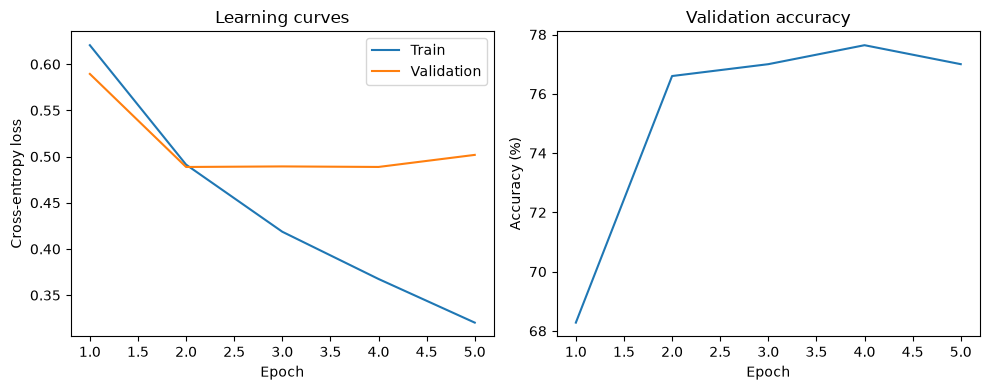

In [39]:
# Run only after training and validation-based model selection are complete.
test_metrics = evaluate(model, test_loader, device)
print(f"Test loss: {test_metrics['loss']:.4f}")
print(f"Test accuracy: {test_metrics['accuracy']:.2f}%")
print("Rubric target (>75%):", "MET" if test_metrics["accuracy"] > 75 else "NOT MET")
(ARTIFACT_DIR / "test_metrics.json").write_text(json.dumps(test_metrics, indent=2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
epochs = [row["epoch"] for row in history]
axes[0].plot(epochs, [row["train_loss"] for row in history], label="Train")
axes[0].plot(epochs, [row["val_loss"] for row in history], label="Validation")
axes[0].set(title="Learning curves", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].legend()
axes[1].plot(epochs, [row["val_accuracy"] for row in history])
axes[1].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "learning_curves.png", dpi=150)
plt.show()


With the accuracy calculated, you can verify if the model meets the project goal of achieving greater than 75% accuracy on the test dataset. 

Try training your model for more than 3 epochs! Try increasing the size of the embedding used in the model. Or try increasing the number of blocks or layers in the model. You may be able to improve the accuracy of your model further!


## Conclusion <a name="conclusion"></a>

The next cell generates the results summary using actual training and test metrics.
No accuracy is claimed until those cells have run.

Key takeaways:
1. Whole-review classification pools token embeddings into two class logits. Padding must
   be excluded from pooling; softmax converts logits to probabilities at inference time.
2. Stratified validation preserves class balance and selects checkpoints without using test
   performance. Training/validation curves help distinguish underfitting from overfitting.
3. Truncation at 128 tokens can discard sentiment evidence in longer reviews. Longer
   contexts may help, but attention computation grows quadratically with sequence length.

This starter trains its transformer weights from scratch; only the tokenizer is pretrained.
For additional experiments, tune context length, embedding size, dropout, and epoch budget
using validation data. A >90% result is an optional stretch goal, not an assumed outcome.

In [40]:
summary = (
    f"SentimentScope results\n"
    f"Train/validation/test reviews: {len(train_dataset)}/{len(val_dataset)}/{len(test_dataset)}\n"
    f"Best epoch: {checkpoint['epoch']}\n"
    f"Selected checkpoint validation accuracy: {checkpoint['validation']['accuracy']:.2f}%\n"
    f"Test accuracy: {test_metrics['accuracy']:.2f}%\n"
    f"Test loss: {test_metrics['loss']:.4f}\n"
    f"Target >75% achieved: {test_metrics['accuracy'] > 75}\n\n"
    "Takeaways: Padding-aware pooling produces a review-level representation. "
    "Validation-based checkpoint selection keeps the test set out of training decisions.\n"
)
print(summary)
(ARTIFACT_DIR / "results_report.txt").write_text(summary)

SentimentScope results
Train/validation/test reviews: 22500/2500/25000
Best epoch: 2
Selected checkpoint validation accuracy: 76.60%
Test accuracy: 75.35%
Test loss: 0.4928
Target >75% achieved: True

Takeaways: Padding-aware pooling produces a review-level representation. Validation-based checkpoint selection keeps the test set out of training decisions.



343

## Load a checkpoint and predict a batch
Run the imports, cleaning function, and model class definitions first in a fresh session.
This interface restores the saved tokenizer and model, including the training context length.
Class 0 is negative and class 1 is positive. Probabilities are model scores, not calibrated confidence.

In [41]:
class SentimentPredictor:
    def __init__(self, artifact_dir, device="cpu"):
        self.device = torch.device(device)
        artifact_dir = Path(artifact_dir)
        saved = torch.load(artifact_dir / "best_model.pt", map_location=self.device, weights_only=True)
        self.config = saved["config"]
        self.tokenizer = AutoTokenizer.from_pretrained(artifact_dir / "tokenizer")
        self.model = DemoGPT(self.config).to(self.device)
        self.model.load_state_dict(saved["model_state_dict"])
        self.model.eval()

    @torch.no_grad()
    def predict(self, texts, batch_size=32):
        if isinstance(texts, str):
            texts = [texts]
        if batch_size < 1:
            raise ValueError("batch_size must be positive")
        if not all(isinstance(text, str) for text in texts):
            raise TypeError("Each review must be a string")
        results = []
        for start in range(0, len(texts), batch_size):
            batch = [clean_review(t) for t in texts[start:start + batch_size]]
            ids = self.tokenizer(batch, padding="max_length", truncation=True,
                                 max_length=self.config["context_size"], return_tensors="pt")["input_ids"]
            probabilities = self.model(ids.to(self.device)).softmax(dim=-1).cpu().tolist()
            for negative, positive in probabilities:
                results.append({"sentiment": "positive" if positive > negative else "negative",
                                "negative_probability": negative, "positive_probability": positive})
        return results

predictor = SentimentPredictor(ARTIFACT_DIR, device=device)
predictor.predict(["An engaging and beautifully acted film.", "A tedious movie with a weak script."])

[{'sentiment': 'positive',
  'negative_probability': 0.4060387909412384,
  'positive_probability': 0.5939611792564392},
 {'sentiment': 'negative',
  'negative_probability': 0.9992005228996277,
  'positive_probability': 0.0007994415936991572}]